# 🎣 Détection de liens de phishing avec le Machine Learning

**Auteur :** Youssef EL AKOUM — élève ingénieur ITI, INSA Rouen Normandie

Petit projet pédagogique : à partir d'une URL seule (sans ouvrir la page), peut-on deviner si c'est un lien de **phishing** ?

Le notebook est organisé en **questions / réponses**, étape par étape :

1. Comprendre le problème
2. Charger et explorer les données
3. Transformer une URL en nombres (*feature engineering*)
4. Entraîner deux modèles simples
5. Évaluer et interpréter
6. Tester sur nos propres liens

## Question 1 — C'est quoi le phishing, et que veut-on faire ?

**Réponse :** le phishing (hameçonnage) consiste à envoyer un faux lien qui imite un site connu (banque, Netflix, La Poste…) pour voler des identifiants ou des données bancaires.

Notre objectif : un **classifieur binaire**.
- Entrée : une URL (texte)
- Sortie : `0` = légitime, `1` = phishing

Exemple de la vie réelle : tu reçois un SMS « Votre colis est bloqué » avec le lien `http://laposte-suivi-colis.xyz/login`. Un humain remarque que le domaine est bizarre ; on veut qu'un modèle apprenne ce genre d'indices.

## Question 2 — Quelles bibliothèques utilise-t-on ?

**Réponse :** `pandas` pour les tableaux, `matplotlib` pour les graphiques, `scikit-learn` pour le Machine Learning, et `re` / `urllib` (inclus dans Python) pour analyser les URLs.

In [1]:
import re
from urllib.parse import urlparse

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Question 3 — D'où viennent les données ?

**Réponse :** le fichier `data/urls.csv` contient **10 000 URLs labellisées** (5 000 légitimes + 5 000 phishing) :
- phishing : URLs vérifiées issues de **PhishTank**
- légitimes : 3 000 URLs de pages issues du jeu **ISCX-URL-2016** (Université du Nouveau-Brunswick) + 2 000 pages d'accueil de sites populaires (top 10 000 des domaines les plus visités)

Pourquoi ce mélange ? Au premier essai, il n'y avait que des URLs ISCX, qui sont presque toutes de longues pages d'articles. Résultat : le modèle classait **toute URL courte** comme phishing, même `wikipedia.org`. Ajouter des pages d'accueil légitimes corrige ce biais.

On a pris le même nombre d'exemples dans chaque classe pour avoir un jeu **équilibré**.

In [2]:
df = pd.read_csv("data/urls.csv")
print("Taille :", df.shape)
df.head()

Taille : (10000, 2)


,url,label
0,http://theloveonherproject.org/antietamx.html,1
1,http://www.ruelala.com/,0
2,http://censor.net.ua/news/335652/sutki_proshli...,0
3,http://creditonebank.com,0
4,http://ixxx.com/,0


## Question 4 — Les classes sont-elles équilibrées ?

**Réponse :** on compte les labels. Si on avait 95 % de légitimes, un modèle qui répond toujours « légitime » aurait 95 % d'accuracy sans rien apprendre. Ici c'est 50/50, donc l'accuracy reste une mesure honnête.

In [3]:
df["label"].value_counts().rename({0: "légitime", 1: "phishing"})

label
phishing    5000
légitime    5000
Name: count, dtype: int64

## Question 5 — À quoi ressemblent les URLs de chaque classe ?

**Réponse :** regardons quelques exemples pour avoir une intuition avant de coder quoi que ce soit.

In [4]:
pd.set_option("display.max_colwidth", 100)
print("=== Légitimes ===")
display(df[df.label == 0]["url"].head(5))
print("=== Phishing ===")
display(df[df.label == 1]["url"].head(5))

=== Légitimes ===


1                                                                                http://www.ruelala.com/
2              http://censor.net.ua/news/335652/sutki_proshli_bez_poter_raneny_pyatero_voinov_spiker_ato
3                                                                               http://creditonebank.com
4                                                                                       http://ixxx.com/
6    http://mic.com/articles/108940/the-very-problematic-reason-this-woman-is-taking-a-stand-against-...
Name: url, dtype: str

=== Phishing ===


0                                   http://theloveonherproject.org/antietamx.html
5                        http://lp2m.umsu.ac.id/wp-includes/widgets/redirect.html
7                                            http://bestfurniturewebfrashop.club/
8     https://etraval.com/.well-known/acme-challenge/update/chaseonline/login.htm
11                  https://www.chikh-ali.com/wp-includes/accesst/wells/wells.htm
Name: url, dtype: str

## Question 6 — Un modèle ne lit pas du texte : comment transformer une URL en nombres ?

**Réponse :** on extrait des **features** simples, qui correspondent aux réflexes d'un humain méfiant :

| Feature | Intuition |
|---|---|
| `longueur_url` | les URLs de phishing cachent souvent le vrai domaine dans un long chemin |
| `longueur_domaine` | domaines inventés parfois très longs (`secure-login-paypal-verify.com`) |
| `nb_points` | beaucoup de sous-domaines : `paypal.com.compte.verif.ru` |
| `nb_tirets` | `amazon-securite-compte.com` |
| `nb_chiffres` | identifiants aléatoires, hébergeurs gratuits |
| `nb_slash` | profondeur du chemin |
| `a_arobase` | `http://google.com@site-pirate.com` → le navigateur va sur le site après le `@` ! |
| `a_ip` | une adresse IP à la place d'un nom de domaine |
| `nb_mots_suspects` | `login`, `verify`, `secure`, `account`, `update`… |

In [5]:
MOTS_SUSPECTS = ["login", "verify", "secure", "account", "update", "bank",
                 "signin", "confirm", "password", "paypal", "webscr", "ebay"]

def extraire_features(url):
    domaine = urlparse(url).netloc
    url_min = url.lower()
    return {
        "longueur_url": len(url),
        "longueur_domaine": len(domaine),
        "nb_points": url.count("."),
        "nb_tirets": url.count("-"),
        "nb_chiffres": sum(c.isdigit() for c in url),
        "nb_slash": url.count("/"),
        "a_arobase": int("@" in url),
        "a_ip": int(bool(re.search(r"\d+\.\d+\.\d+\.\d+", domaine))),
        "nb_mots_suspects": sum(mot in url_min for mot in MOTS_SUSPECTS),
    }

# Test rapide sur un exemple
extraire_features("http://192.168.1.10/paypal-login/verify.php")

{'longueur_url': 43,
 'longueur_domaine': 12,
 'nb_points': 4,
 'nb_tirets': 1,
 'nb_chiffres': 9,
 'nb_slash': 4,
 'a_arobase': 0,
 'a_ip': 1,
 'nb_mots_suspects': 3}

## Question 7 — Comment appliquer cette fonction à toutes les URLs ?

**Réponse :** avec `apply`, puis on transforme la liste de dictionnaires en tableau. `X` = les features, `y` = la réponse attendue (le label).

In [6]:
X = pd.DataFrame(df["url"].apply(extraire_features).tolist())
y = df["label"]
X.head()

,longueur_url,longueur_domaine,nb_points,nb_tirets,nb_chiffres,nb_slash,a_arobase,a_ip,nb_mots_suspects
0,45,23,2,0,0,3,0,0,0
1,23,15,2,0,0,3,0,0,0
2,89,13,2,0,6,5,0,0,0
3,24,17,1,0,0,2,0,0,1
4,16,8,1,0,0,3,0,0,0


## Question 8 — Les features sont-elles vraiment différentes entre les deux classes ?

**Réponse :** on compare la moyenne de chaque feature par classe. Si les moyennes sont proches, la feature n'aidera pas beaucoup.

In [7]:
X.groupby(y).mean().rename(index={0: "légitime", 1: "phishing"}).round(2).T

label,légitime,phishing
longueur_url,77.26,81.30
longueur_domaine,12.61,20.22
nb_points,1.80,2.40
nb_tirets,3.87,1.00
nb_chiffres,8.88,10.50
nb_slash,4.34,5.21
a_arobase,0.00,0.04
a_ip,0.00,0.01
nb_mots_suspects,0.03,0.36


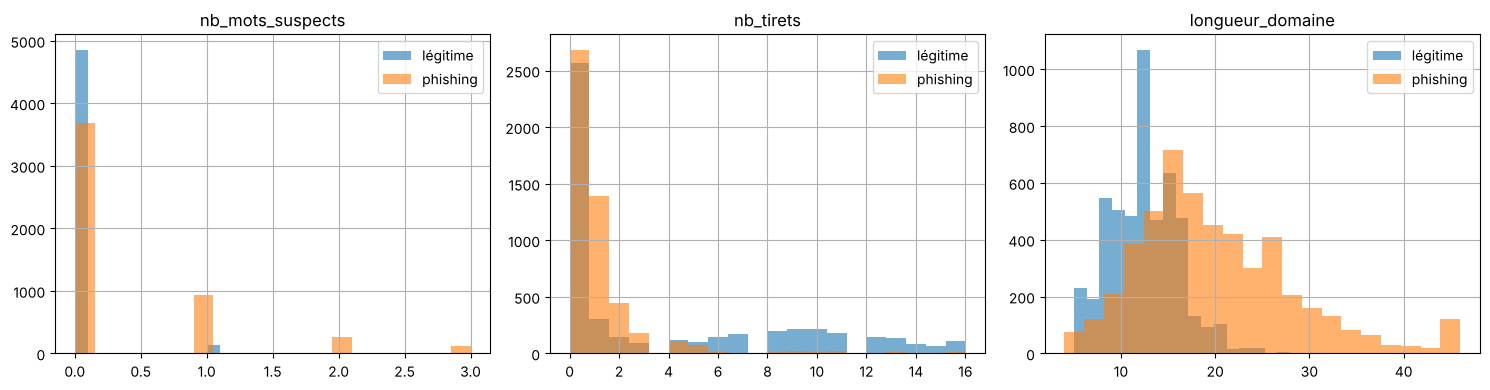

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["nb_mots_suspects", "nb_tirets", "longueur_domaine"]):
    X[y == 0][col].clip(upper=X[col].quantile(0.99)).hist(ax=ax, bins=20, alpha=0.6, label="légitime")
    X[y == 1][col].clip(upper=X[col].quantile(0.99)).hist(ax=ax, bins=20, alpha=0.6, label="phishing")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

**Lecture :** les URLs de phishing contiennent nettement plus de mots suspects (`login`, `verify`…) et ont des noms de domaine plus longs. Point surprenant : les URLs légitimes ont plus de tirets (les titres d'articles du type `/la-bourse-chute-encore`). Il faut toujours vérifier ses intuitions sur les données !

## Question 9 — Pourquoi séparer les données en train et test ?

**Réponse :** un modèle évalué sur les données qu'il a apprises, c'est comme un élève corrigé sur les exercices dont il a déjà vu la correction : la note ne veut rien dire.
On garde donc **20 %** des URLs de côté (test), jamais vues pendant l'entraînement.

`stratify=y` garde la même proportion phishing / légitime dans les deux parties.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (8000, 9) | Test : (2000, 9)


## Question 10 — Premier modèle : la régression logistique

**Réponse :** c'est le modèle de base pour la classification binaire. Il donne un poids à chaque feature et calcule une probabilité d'être du phishing.
On met un `StandardScaler` avant, car les features n'ont pas la même échelle (`longueur_url` ~100, `a_arobase` = 0 ou 1).

In [10]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

pred_lr = logreg.predict(X_test)
print("Accuracy régression logistique :", round(accuracy_score(y_test, pred_lr), 3))

Accuracy régression logistique : 0.833


## Question 11 — Peut-on faire mieux avec un Random Forest ?

**Réponse :** un Random Forest combine beaucoup d'arbres de décision (des suites de questions « si… alors… »). Il capture des règles non linéaires, par exemple « *peu de points* **mais** *beaucoup de chiffres* → suspect ». Pas besoin de normaliser les features.

In [11]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
print("Accuracy Random Forest :", round(accuracy_score(y_test, pred_rf), 3))

Accuracy Random Forest : 0.959


## Question 12 — L'accuracy suffit-elle ?

**Réponse :** non. En sécurité, les deux erreurs n'ont pas le même coût :
- **Faux négatif** (phishing classé légitime) : l'utilisateur clique et se fait voler ses identifiants → grave.
- **Faux positif** (site légitime bloqué) : gênant, mais pas dangereux.

On regarde donc la **precision**, le **recall** (part des phishings réellement détectés) et la **matrice de confusion**.

              precision    recall  f1-score   support

    légitime       0.95      0.97      0.96      1000
    phishing       0.97      0.94      0.96      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000



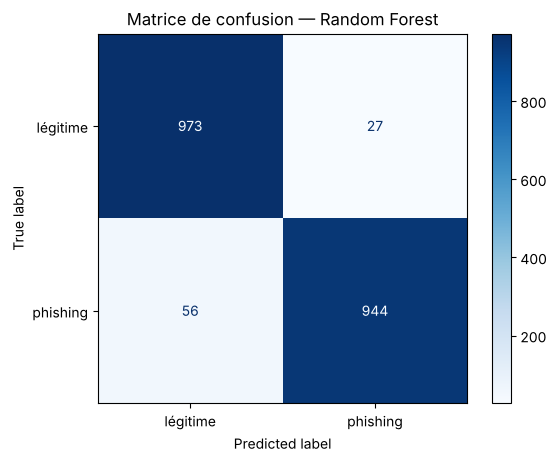

In [12]:
print(classification_report(y_test, pred_rf, target_names=["légitime", "phishing"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_rf, display_labels=["légitime", "phishing"], cmap="Blues"
)
plt.title("Matrice de confusion — Random Forest")
plt.show()

## Question 13 — Quelles features le modèle utilise-t-il le plus ?

**Réponse :** le Random Forest donne une *importance* à chaque feature. Ça permet d'expliquer le modèle au lieu de le traiter comme une boîte noire.

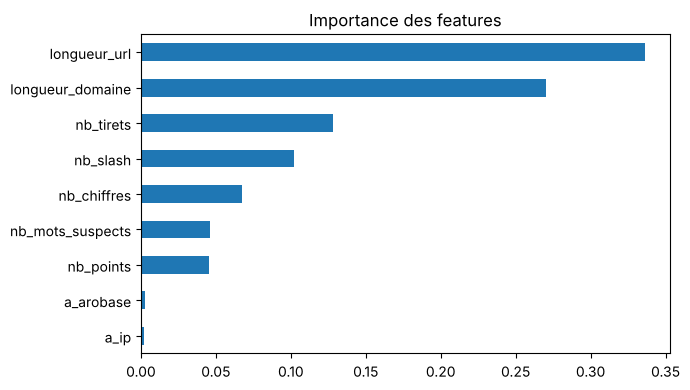

In [13]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(7, 4), title="Importance des features")
plt.tight_layout()
plt.show()

## Question 14 — Comment l'utiliser sur un lien qu'on reçoit ?

**Réponse :** on écrit une petite fonction `analyser(url)` qui extrait les features et renvoie la probabilité de phishing.

In [14]:
def analyser(url):
    features = pd.DataFrame([extraire_features(url)])
    proba = rf.predict_proba(features)[0][1]
    verdict = "⚠️ PHISHING" if proba >= 0.5 else "✅ légitime"
    print(f"{verdict:12} ({proba:.0%})  {url}")

exemples = [
    "http://www.insa-rouen.fr/",
    "http://en.wikipedia.org/wiki/Machine_learning",
    "http://www.lemonde.fr/economie/article/2020/03/12/la-bourse-chute_6032.html",
    "http://paypal.com.secure-login.verify-account.ru/signin",
    "http://192.168.0.12/bank/update/login.php",
    "http://amazon-account-confirm-update.com/webscr?cmd=login",
]
for url in exemples:
    analyser(url)

✅ légitime   (26%)  http://www.insa-rouen.fr/
⚠️ PHISHING  (100%)  http://en.wikipedia.org/wiki/Machine_learning
⚠️ PHISHING  (99%)  http://www.lemonde.fr/economie/article/2020/03/12/la-bourse-chute_6032.html
⚠️ PHISHING  (100%)  http://paypal.com.secure-login.verify-account.ru/signin
⚠️ PHISHING  (100%)  http://192.168.0.12/bank/update/login.php
⚠️ PHISHING  (100%)  http://amazon-account-confirm-update.com/webscr?cmd=login


## Question 15 — Le modèle a 96 % sur le test… mais il se trompe sur Wikipedia et Le Monde. Pourquoi ?

**Réponse :** c'est le résultat le plus intéressant du projet.

Le jeu de test vient **des mêmes sources** que le jeu d'entraînement : les URLs légitimes y ressemblent à celles du jeu ISCX (beaucoup de tirets dans les titres d'articles, des sites de 2016…). Le modèle a appris ces particularités, pas « ce qu'est un site légitime » en général.

Quand on lui donne une vraie URL d'aujourd'hui qui ne ressemble pas à ses données (`/wiki/Machine_learning` : pas de tiret, chemin court), il se trompe avec beaucoup de confiance. On appelle ça un **décalage de distribution** (*distribution shift*).

👉 Leçon : une bonne note sur le jeu de test ne garantit pas que le modèle marche dans le monde réel. Il faut toujours le tester sur des exemples **extérieurs** au dataset.

## Question 16 — Quelles sont les autres limites de ce projet ?

**Réponse :** c'est volontairement un projet simple. Les limites principales :

1. **Biais des données.** Dans ce jeu, presque toutes les URLs légitimes commencent par `http://` alors que beaucoup de phishings sont en `https://`. C'est pour ça qu'on **n'a pas** mis de feature « https » : le modèle aurait appris un raccourci faux (aujourd'hui, quasiment tous les sites légitimes sont en https).
2. **Données datées** (≈ 2016–2020) : les attaquants changent de techniques.
3. **On ne regarde que l'URL**, pas le contenu de la page, l'âge du domaine ou sa réputation.
4. Un attaquant qui connaît les features peut les contourner (URL courte, pas de mot suspect).

## Question 17 — Comment l'améliorer ?

**Réponse :**
- ajouter des features : TLD suspect (`.xyz`, `.tk`), entropie du domaine, âge du domaine (WHOIS) ;
- utiliser des **n-grammes de caractères** (TF-IDF) directement sur l'URL ;
- tester d'autres modèles (XGBoost) et une validation croisée ;
- **en priorité** : entraîner sur des données plus récentes et plus variées (PhishTank, OpenPhish pour le phishing ; liste Tranco + vraies pages internes pour les sites légitimes), pour corriger le problème de la question 15 ;
- déployer le modèle dans une petite API ou une extension de navigateur.

## ✅ Conclusion

Avec seulement **9 features très simples** extraites du texte de l'URL, un Random Forest atteint environ **96 % d'accuracy** sur le jeu de test, contre environ 83 % pour la régression logistique. Mais le test sur de vraies URLs montre que le modèle dépend beaucoup de ses données d'entraînement.
Le projet montre la démarche complète d'un projet de ML : comprendre le problème, explorer les données, construire des features, entraîner, évaluer avec les bonnes métriques et **garder un regard critique sur les biais des données**.